--- Price Analysis for Example Product ---
Data range: 2026-10-18 to 2026-10-27
Current Price:  990,000 UGX
Average Price:  1,069,000 UGX
💰 GOOD DEAL! Current price is 7.4% below the average.


C:\Users\HP\AppData\Local\Temp\ipykernel_31468\1526934348.py:71: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\HP\AppData\Local\Temp\ipykernel_31468\1526934348.py:74: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) DejaVu Sans.
  plt.savefig('price_history_chart.png')


Chart saved as price_history_chart.png


C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


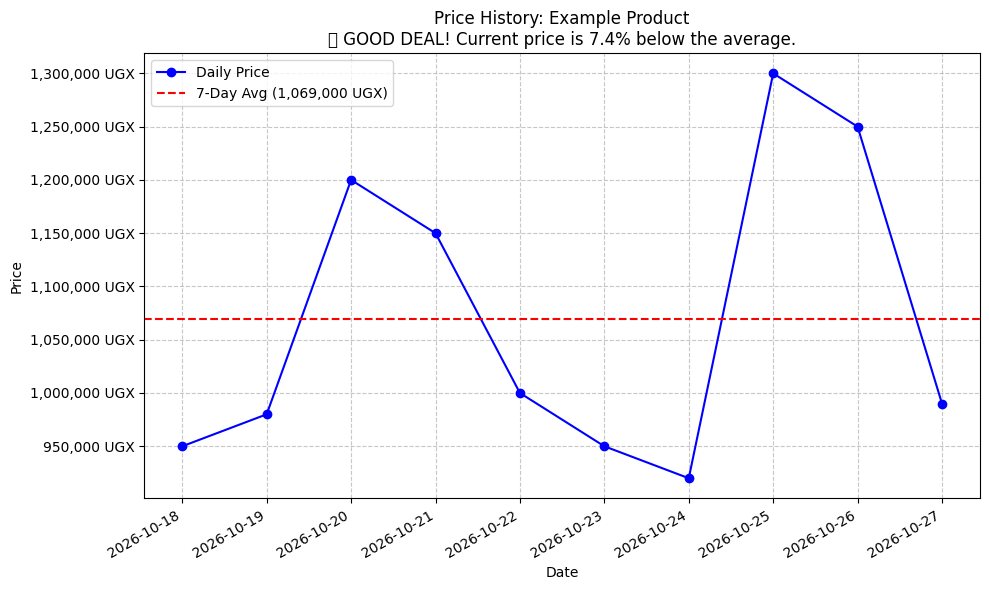

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import datetime

# --- CONFIG ---
# Change to 'jumia_price_history.csv' when you have real data
CSV_FILE = 'test_price_history.csv' 
PRODUCT_NAME = "Example Product" # You could make the scraper save this to a variable

def analyze_prices(csv_path):
    try:
        df = pd.read_csv(csv_path)
        
        # Convert Date column to datetime objects for better plotting
        df['Date'] = pd.to_datetime(df['Date'])
        
        # Sort by date just in case
        df = df.sort_values('Date')

        # --- THE COMPARISON LOGIC ---
        current_price = df['Price_UGX'].iloc[-1]
        average_price = df['Price_UGX'].mean()
        highest_price = df['Price_UGX'].max()
        lowest_price = df['Price_UGX'].min()

        print(f"--- Price Analysis for {PRODUCT_NAME} ---")
        print(f"Data range: {df['Date'].iloc[0].date()} to {df['Date'].iloc[-1].date()}")
        print(f"Current Price:  {current_price:,.0f} UGX")
        print(f"Average Price:  {average_price:,.0f} UGX")
        
        diff_percent = ((current_price - average_price) / average_price) * 100
        
        if diff_percent < 0:
            status = "BELOW"
            color = "green"
            message = f"💰 GOOD DEAL! Current price is {abs(diff_percent):.1f}% below the average."
        elif diff_percent > 0:
            status = "ABOVE"
            color = "red"
            message = f"⚠️ BAD DEAL. Current price is {abs(diff_percent):.1f}% above the average."
        else:
            status = "AT"
            color = "gray"
            message = "Current price is equal to the average."
            
        print(message)

        # --- VISUALIZATION ---
        plt.figure(figsize=(10, 6))
        
        # Plot the actual price line
        plt.plot(df['Date'], df['Price_UGX'], marker='o', linestyle='-', color='blue', label='Daily Price')
        
        # Add the average price as a horizontal dashed red line
        plt.axhline(y=average_price, color='r', linestyle='--', label=f'7-Day Avg ({average_price:,.0f} UGX)')
        
        # Formatting the Y-axis for Ugandan Shillings (UGX)
        formatter = ticker.StrMethodFormatter('{x:,.0f} UGX')
        plt.gca().yaxis.set_major_formatter(formatter)
        
        # Formatting X-axis dates
        plt.gcf().autofmt_xdate() # Rotate dates so they don't overlap
        
        plt.title(f'Price History: {PRODUCT_NAME}\n{message}')
        plt.xlabel('Date')
        plt.ylabel('Price')
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.7)
        
        plt.tight_layout()
        
        # Save plot as image for TikTok/README
        plt.savefig('price_history_chart.png')
        print("Chart saved as price_history_chart.png")
        
        # Show plot (optional, depends on your environment)
        # plt.show()

    except FileNotFoundError:
        print(f"Error: {csv_path} not found. Run the scraper or test data generator first.")
    except Exception as e:
        print(f"An error occurred during analysis: {e}")

if __name__ == "__main__":
    analyze_prices(CSV_FILE)